# 01 - Data acquisition and EDA
Heart Disease UCI (Cleveland, 303 patients, 13 predictors).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, seaborn as sns
import matplotlib.pyplot as plt
from src.data import load_raw, clean
from src import eda
from IPython.display import Image, display
sns.set_theme(style='whitegrid')

## 1. Load raw file and inspect
Run `python scripts/download_data.py` first if `data/raw` is empty.

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
print('Missing values (raw, coded as ?):')
print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nOriginal target distribution (0-4):')
print(raw['target'].value_counts().sort_index())

Missing values (raw, coded as ?):
ca      4
thal    2
dtype: int64

Original target distribution (0-4):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


## 2. Cleaning
Target is binarised (0 = healthy, 1-4 = disease). Missing `ca`/`thal` values are kept as NaN and imputed *inside* the sklearn pipeline so imputers are fit on training folds only.

In [4]:
df = clean(raw)
print(df.shape, df['target'].value_counts().to_dict())
df.describe().T

(303, 14) {0: 164, 1: 139}


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 3. Class balance

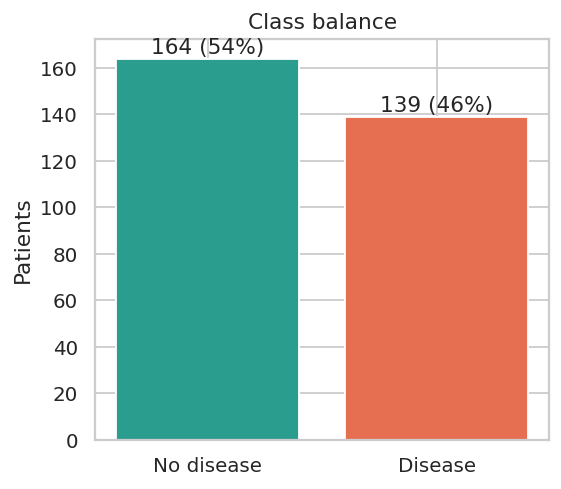

In [5]:
eda.class_balance(df); display(Image(str(eda.FIG_DIR/'class_balance.png')))

The classes are nearly balanced (54% / 46%), so accuracy is meaningful and no resampling is needed; recall and ROC-AUC are still tracked because missing a sick patient is the costly error.

## 4. Distributions of numeric features

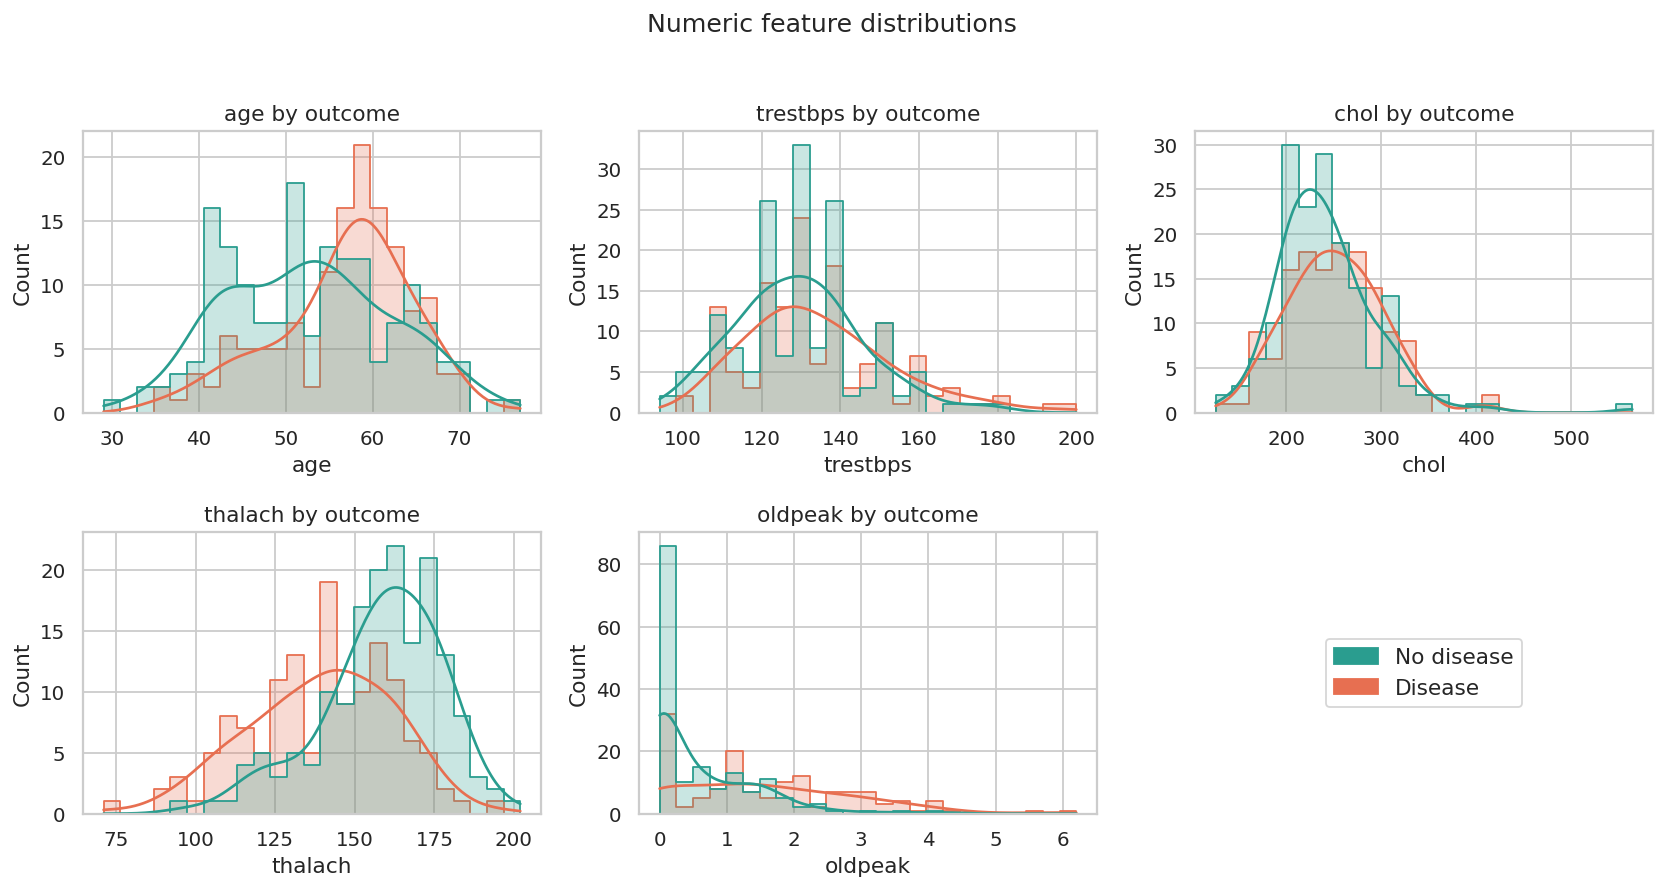

In [6]:
eda.numeric_histograms(df); display(Image(str(eda.FIG_DIR/'numeric_histograms.png')))

## 5. Categorical features vs outcome

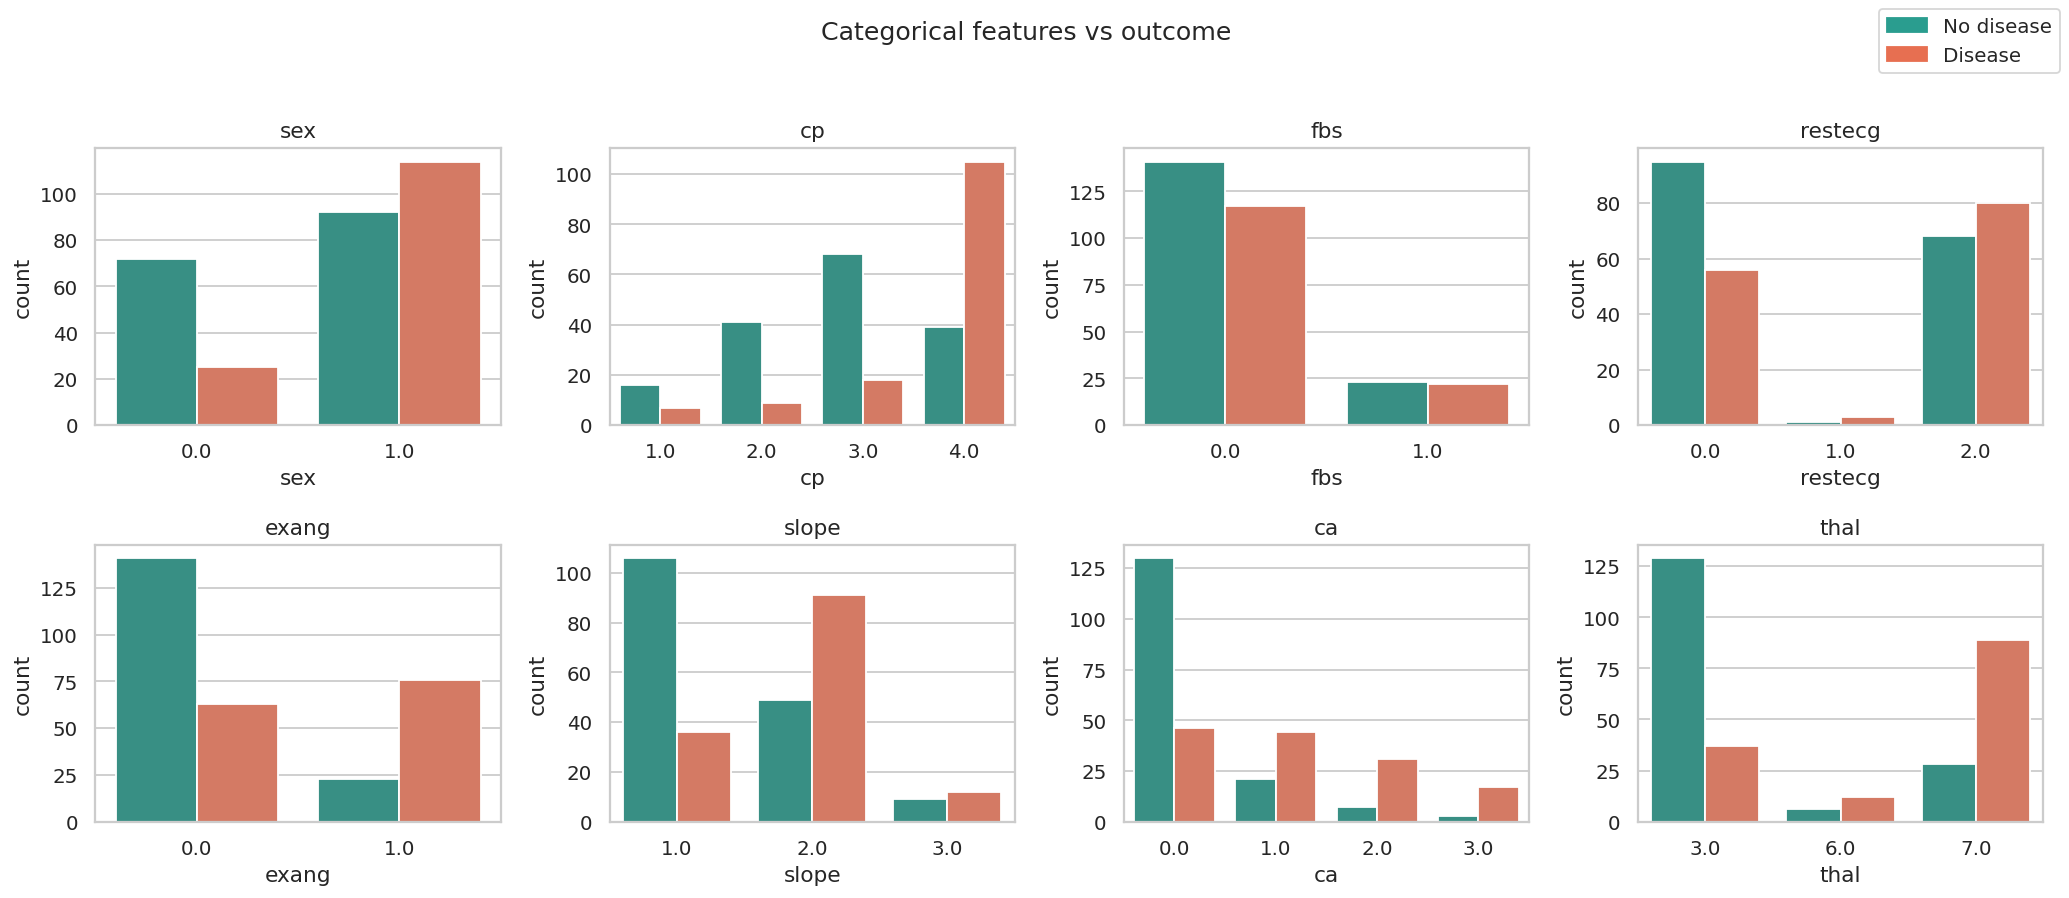

In [7]:
eda.categorical_counts(df); display(Image(str(eda.FIG_DIR/'categorical_counts.png')))

## 6. Correlations

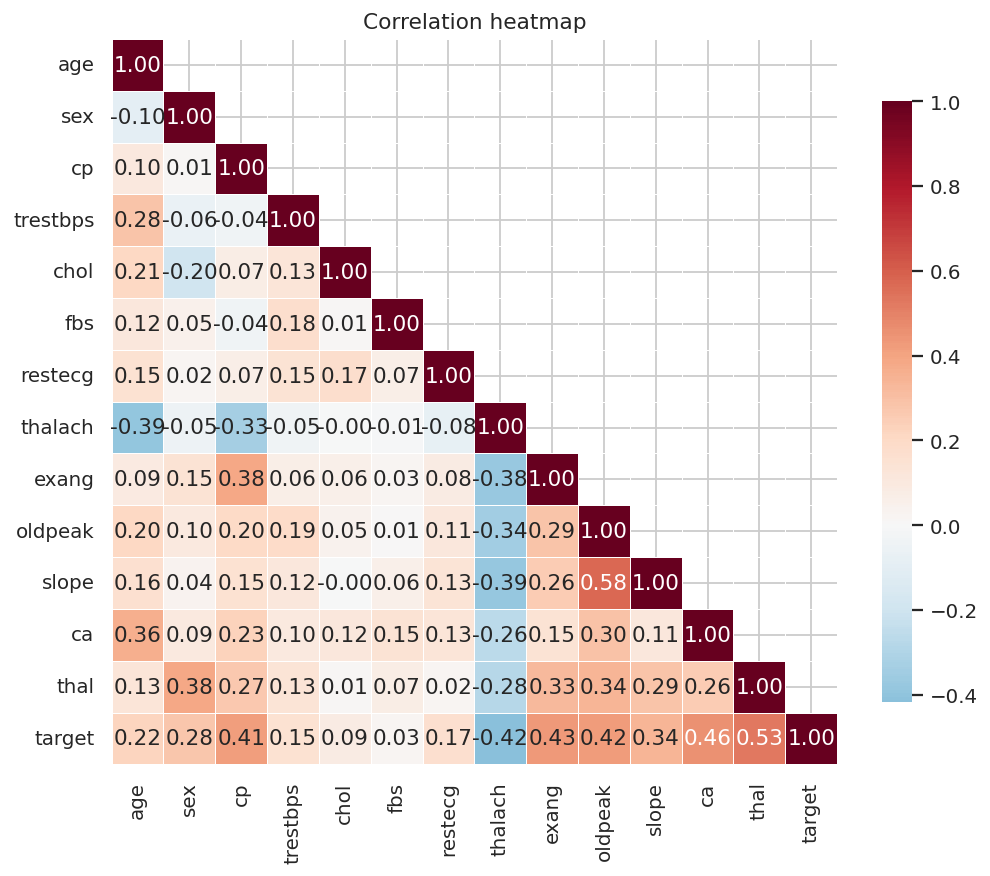

In [8]:
eda.correlation_heatmap(df); display(Image(str(eda.FIG_DIR/'correlation_heatmap.png')))

In [9]:
df.corr()['target'].drop('target').sort_values(key=abs, ascending=False)

thal        0.525689
ca          0.460442
exang       0.431894
oldpeak     0.424510
thalach    -0.417167
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
Name: target, dtype: float64

**Takeaways**: `thal`, `ca`, `oldpeak`, `exang`, `cp` and `thalach` carry most of the signal. `thalach` correlates negatively with age and with disease, which motivated the engineered `hr_ratio = thalach / (220 - age)` feature. `chol` and `fbs` are weak predictors on their own.

## 7. Outliers

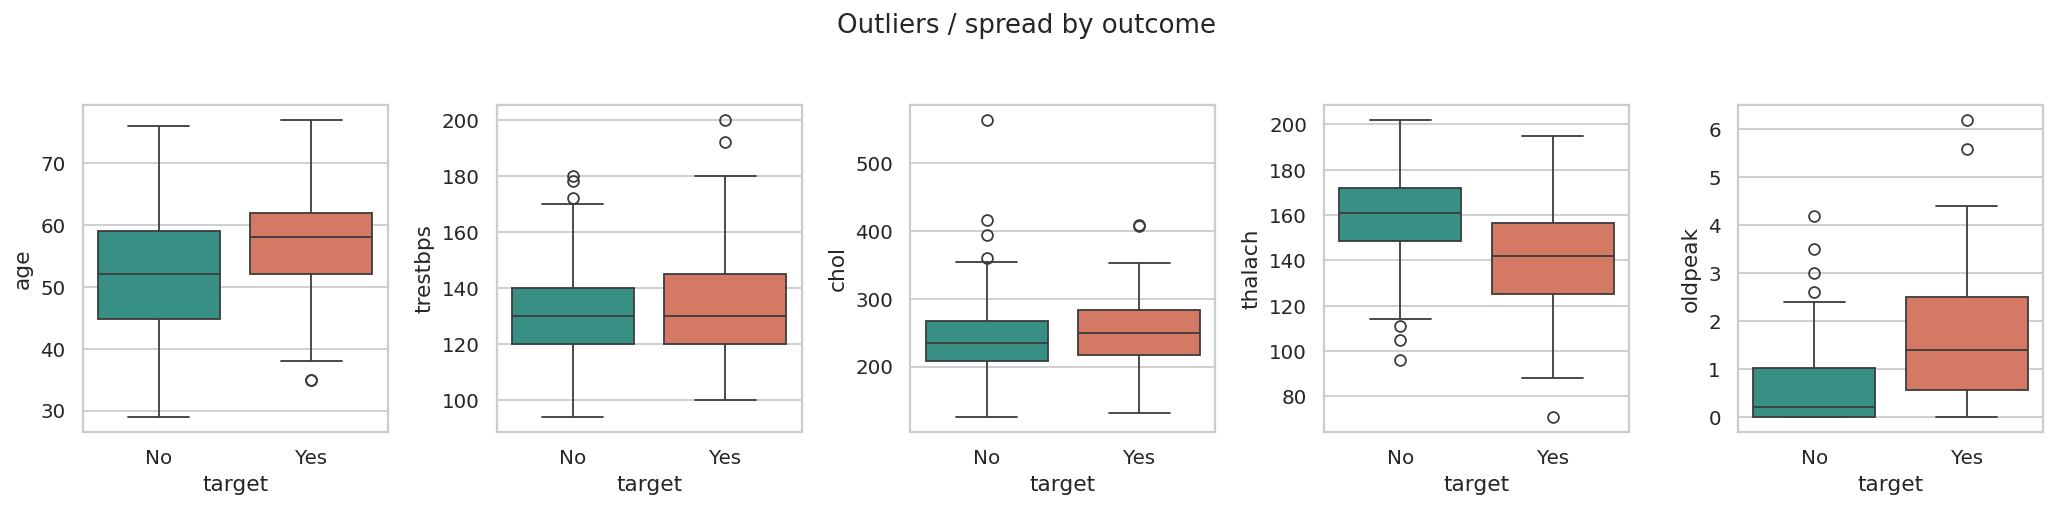

In [10]:
eda.boxplots(df); display(Image(str(eda.FIG_DIR/'boxplots.png')))

In [11]:
df.to_csv(ROOT/'data'/'heart_clean.csv', index=False); print('saved cleaned dataset')

saved cleaned dataset
